<a href="https://colab.research.google.com/github/Rigtsu/image_processing/blob/main/hw6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

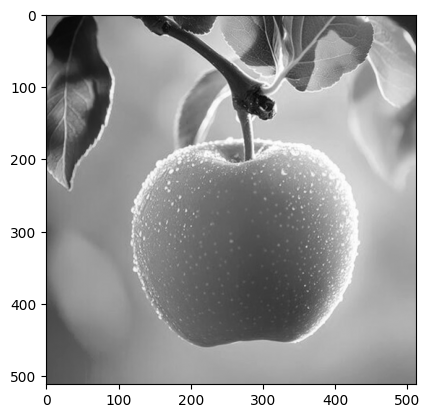

In [14]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

image = cv.imread('green_apple.jpg')
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

Реализация алгоритма Haar

In [15]:
def step_rows(image):
    rows, cols = image.shape
    result = np.zeros_like(image, dtype=np.float32)
    for i in range(rows):
        for j in range(0, cols, 2):
            a, b = image[i, j], image[i, j+1]
            result[i, j//2] = (a + b) / 2
            result[i, j//2 + cols // 2] = (a - b) / 2
    return result

def step_cols(image):
    rows, cols = image.shape
    result = np.zeros_like(image, dtype=np.float32)
    for i in range(0, rows, 2):
        for j in range(cols):
            a, b = image[i, j], image[i+1, j]
            result[i//2, j] = (a + b) / 2
            result[i//2 + rows // 2, j] = (a - b) / 2
    return result

In [16]:
def normalize(arr):
    arr_min, arr_max = arr.min(), arr.max()
    if arr_max - arr_min < 1e-8:
        return np.zeros_like(arr, dtype=np.uint8)
    return np.uint8((arr - arr_min) / (arr_max - arr_min) * 255)

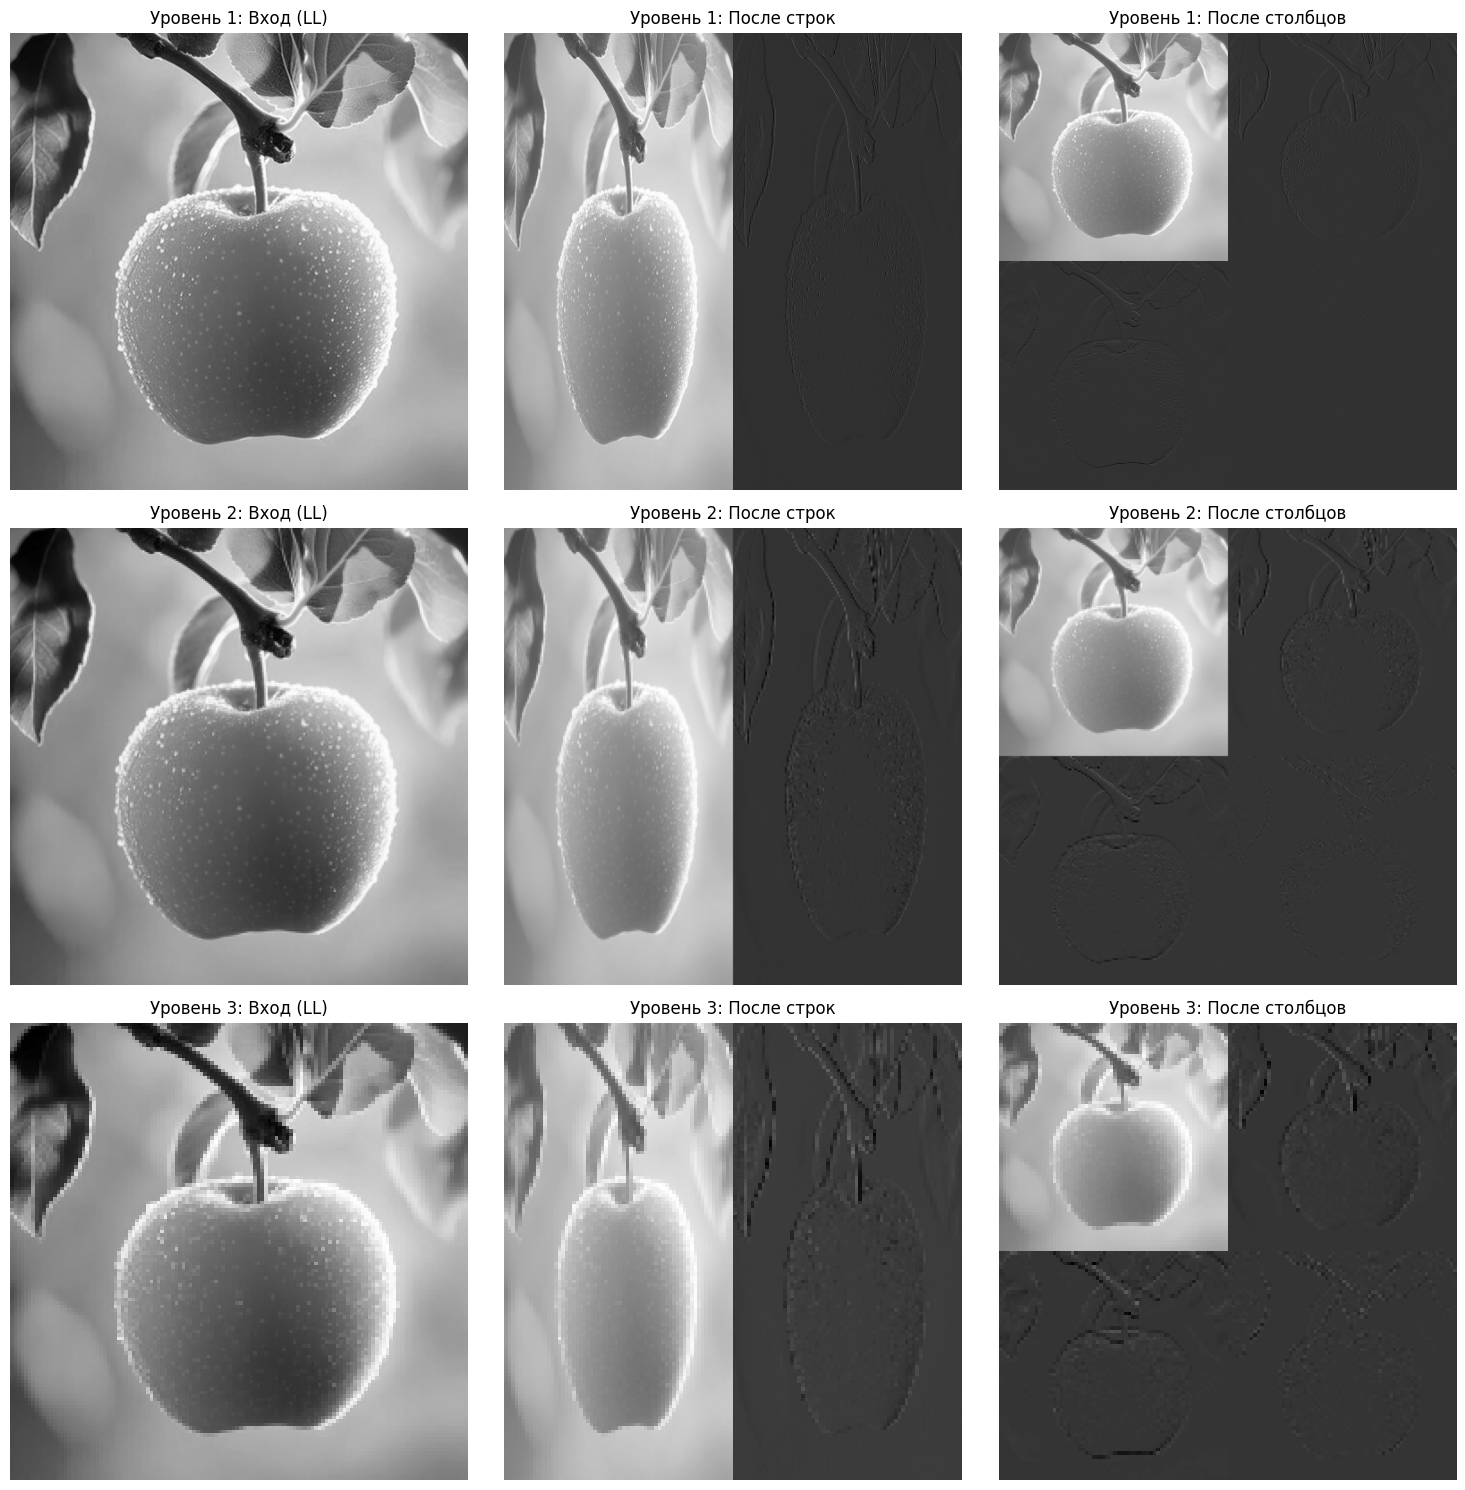

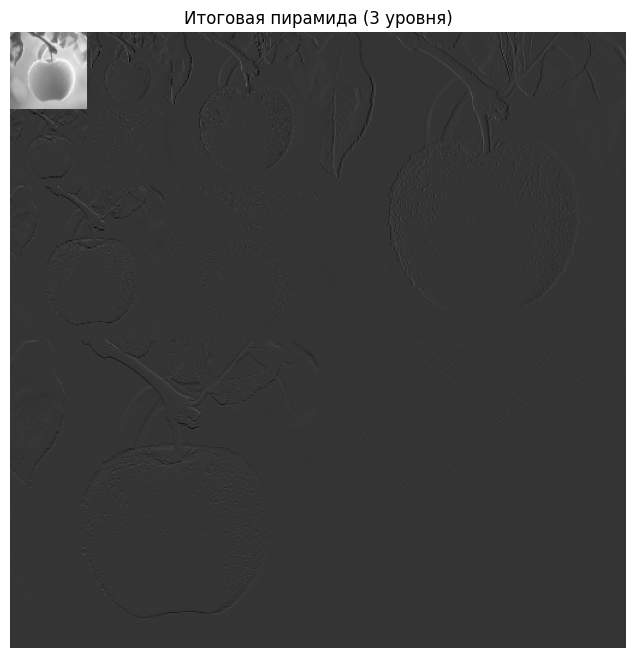

In [20]:
def haar_decompose(image, levels=3):
    pyramid = image.copy()
    current_LL = image

    fig, ax = plt.subplots(levels, 3, figsize=(15, 15))

    for level in range(levels):
        rows_res = step_rows(current_LL)
        cols_res = step_cols(rows_res)

        r, c = current_LL.shape
        pyramid[:r, :c] = cols_res

        ax[level, 0].imshow(normalize(current_LL), cmap="gray")
        ax[level, 0].set_title(f"Уровень {level+1}: Вход (LL)")

        ax[level, 1].imshow(normalize(rows_res), cmap="gray")
        ax[level, 1].set_title(f"Уровень {level+1}: После строк")

        ax[level, 2].imshow(normalize(cols_res), cmap="gray")
        ax[level, 2].set_title(f"Уровень {level+1}: После столбцов")

        current_LL = cols_res[:r//2, :c//2]

    for a in ax.flat:
        a.axis("off")

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(normalize(pyramid), cmap="gray")
    plt.title("Итоговая пирамида (3 уровня)")
    plt.axis("off")
    plt.show()


image_float = np.float32(image_gray) / 255.0
rows, cols = image_float.shape
image_float = image_float[:(rows // 8) * 8, :(cols // 8) * 8]

haar_decompose(image_float, levels=3)